In [1]:
cd ./wrkDir/s18-2/

/work/xiangchong.li/work/S18ASimHSC/s18-2


In [8]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import sim_analysis_utilities as utilities

import matplotlib
import matplotlib.pyplot as plt
cm  = plt.cm.get_cmap('RdYlBu')

import logging
logging.basicConfig(filename='6-ReGaus_selBias.log',level=logging.INFO)

anaDir='./anaCat'
pltDir='./plot/selBias'
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim.h5')
magA10_lowers=np.linspace(23,24.5,6)
nbin_1d=len(magA10_lowers)
print(magA10_lowers)

Populating the interactive namespace from numpy and matplotlib
[23.  23.3 23.6 23.9 24.2 24.5]


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/IPython/core/magics/pylab.py:160: UserWarning: pylab import has clobbered these variables: ['cm']
`%matplotlib` prevents importing * from pylab and numpy
  "\n`%matplotlib` prevents importing * from pylab and numpy"


# Selection Bias of Resolution Cut
## Preparation

Read data and apply weak lensing. 90 degree rotation is applied for cuts except the resolution cut.

In [9]:
# Read catalog
dataF =   pd.read_hdf(inFname)
data  =   dataF.to_records(index=True)
# Apply WL cut for simulations
# NOTE: We are using numpy record to do the selection
# TODO: Use pandas.DataFrame based in the future
min_snr=10
max_snr=200
max_magA10=None
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.

# Whether to remove selection bias
force_90_pair=True

wlmaskS    =   utilities.galaxy_selector(catalog=data,
                min_snr=min_snr, #snr
                max_snr=max_snr,
                max_magA10=max_magA10, #magA10
                min_res=min_res, #res
                max_mag=max_mag, #mag
                max_logb=max_logb,#logb
                force_90_pair=force_90_pair,
                max_e=max_e,     #absE
                max_sigma_e=max_sigma_e) #sigma_e
dataF['wlmask_90rot_noMagA10']=wlmaskS
dataU=data[wlmaskS]

In [10]:
# Determines the selection for different upper bounds
if force_90_pair:
    assert np.all(dataU[0::2]['ipos']==(dataU['ipos'][1::2]-1))
    assert np.all(dataU[0::2]['weight']==(dataU['weight'][1::2]))
slide_test_bins=np.zeros(len(dataU),dtype=np.uint64)
for iu,lower in enumerate(magA10_lowers):
    tmp_msk=(dataU['magA10']>lower)
    if force_90_pair:
        tmp_msk[1::2]=tmp_msk[0::2]
    tmp_msk   &=   (dataU['magA10']<25.5)
    slide_test_bins[tmp_msk]=(slide_test_bins[tmp_msk]|np.uint(2**iu))
dataF['selbias_magA10_ibins']=np.zeros(len(dataF),dtype=np.uint64)
dataF['selbias_magA10_ibins'][wlmaskS]=slide_test_bins
dataF.to_hdf(inFname,key='data')

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  del sys.path[0]


0.535013653884159


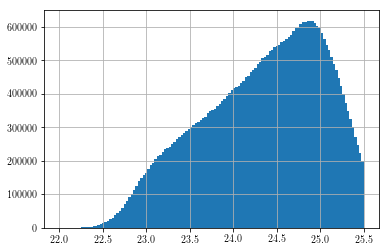

In [13]:
plt.hist(dataU['magA10'],128,[22,25.5],weights=shape_weight)
plt.grid()
print(np.sum(shape_weight[dataU['magA10']<24.5])/np.sum(shape_weight[dataU['magA10']<25.5]))

## Load outcomes of reGaus_shearTest.py

In [14]:
shearBinName=   os.path.join(pltDir,'shear_selbias_magA10.npy')
outcomes=np.load(shearBinName)

nsim   =   len(outcomes)
psf_e1 =   np.zeros(nsim)
psf_e2 =   np.zeros(nsim)
weight =   np.zeros(nsim)
g1_true=   np.zeros(nsim)
g2_true=   np.zeros(nsim)
g1_bins=   np.zeros((nbin_1d,nsim))
g2_bins=   np.zeros((nbin_1d,nsim))
sigma_g_bins=   np.zeros((nbin_1d,nsim))

for iout,outcome in enumerate(outcomes):
    g1_true[iout]  =   outcome[0]
    g2_true[iout]  =   outcome[1]
    g1_bins[:,iout]  =   outcome[2]
    g2_bins[:,iout]  =   outcome[3]
    sigma_g_bins[:,iout]  =   outcome[4]
    psf_e1[iout]  =   outcome[5]
    psf_e2[iout]  =   outcome[6]
    weight[iout]  =   outcome[7]
    
m1_bins    =   np.zeros(nbin_1d)
a1_bins    =   np.zeros(nbin_1d)
sigm1_bins =   np.zeros(nbin_1d)
siga1_bins =   np.zeros(nbin_1d)

# For each of the sliding bins in SNR/resolution.
for j in range(nbin_1d):
    sigma_vals = sigma_g_bins[j,:]
    division_val = np.sqrt(weight)
    division_val[division_val<1.e-6] = 1.e-6
    sigma_vals /= division_val
    # remove unrealistic sim
    tmp_use = (sigma_vals < 1.e+10)
    # get multiplicative bias and additive bias
    m1_bins[j],a1_bins[j], \
    sigm1_bins[j],siga1_bins[j]= \
        utilities.get_m_c_a(g1_bins[j,tmp_use],
                            g2_bins[j,tmp_use],
                            g1_true[tmp_use],
                            g2_true[tmp_use],
                            psf_e1[tmp_use],
                            psf_e2[tmp_use],
                            sigma_vals[tmp_use],
                            separate_components=False)

## Plot multiplicative bias and additive bias

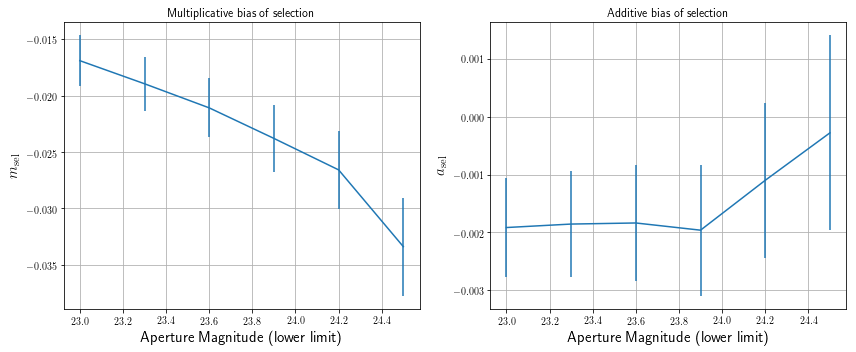

In [15]:
fig = plt.figure(figsize=(12,5))

# Plot residuals
ax = fig.add_subplot(1,2,1)
ax.errorbar(magA10_lowers, m1_bins,sigm1_bins)
plt.xlabel('Aperture Magnitude (lower limit)',fontsize=15)
plt.ylabel(r'$m_{\rm{sel}}$',fontsize=15)
plt.title('Multiplicative bias of selection')
plt.grid()


# Plot significance
ax = fig.add_subplot(1,2,2)
ax.errorbar(magA10_lowers, a1_bins,siga1_bins)
plt.xlabel('Aperture Magnitude (lower limit)',fontsize=15)
plt.ylabel(r'$a_{\rm{sel}}$',fontsize=15)
plt.title('Additive bias of selection')
plt.grid()
plt.tight_layout()
#plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))

## Divide Density at $\rm{magA10}=25.5$

In [11]:
magA10=dataU['magA10']
shape_weight = utilities.get_weight_model(dataU)*dataU['weight']
mask=(magA10<25.5)

p_edges=np.zeros(nbin_1d)
n_hist=100
bin_size = (25.5-23)/n_hist
n_first_bin = np.sum(shape_weight[mask&(magA10 >= 25.5 - bin_size)])
print(bin_size)
for i in range(nbin_1d):
    magA10Min=magA10_lowers[i]
    p_edges[i] = n_first_bin / (np.sum(shape_weight[mask&(magA10>=magA10Min)]) * bin_size)
    

0.025


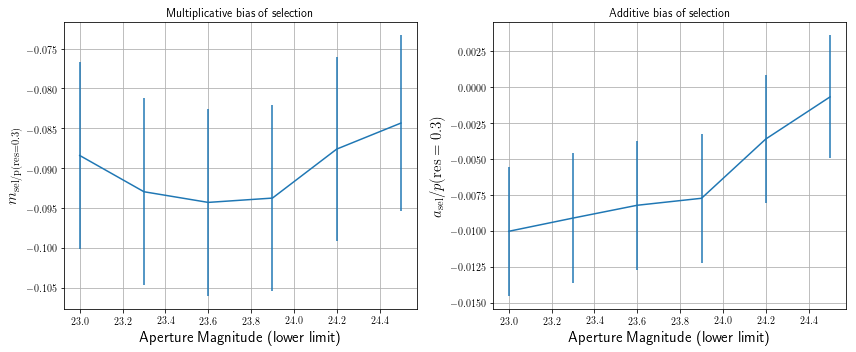

In [16]:
fig = plt.figure(figsize=(12,5))

# Plot residuals
ax = fig.add_subplot(1,2,1)
ax.errorbar(magA10_lowers, m1_bins/p_edges,sigm1_bins/p_edges)
plt.xlabel('Aperture Magnitude (lower limit)',fontsize=15)
plt.ylabel(r'$m_{\rm{sel}/p(\rm{res}=0.3)}$',fontsize=15)
plt.title('Multiplicative bias of selection')
plt.grid()


# Plot significance
ax = fig.add_subplot(1,2,2)
ax.errorbar(magA10_lowers, a1_bins/p_edges,siga1_bins/p_edges)
plt.xlabel('Aperture Magnitude (lower limit)',fontsize=15)
plt.ylabel(r'$a_{\rm{sel}}/p(\rm{res}=0.3)$',fontsize=15)
plt.title('Additive bias of selection')
plt.grid()
plt.tight_layout()
#plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))

## Simple Test

In [18]:
dataF=dataF[wlmaskS&(dataF['magA10']<25.5)]
test_weight_bias=True
indexList=  dataF.index.levels[1]
outData=[]
for index in indexList:
    catalog =   dataF.xs(index,level='isim').to_records(index=False)
    reweight     =   catalog['weight'][0]
    if len(catalog)<50 or reweight<1.e-6:
        continue
    # Force the same weight and Response
    e_rms = utilities.get_erms_model(catalog)
    shape_weights = utilities.get_weight_model(catalog)*catalog['weight']
    if not test_weight_bias:
        shape_weights[1::2] = shape_weights[0::2]
        e_rms[1::2] = e_rms[0::2]
    
    # True shear
    g1_true, g2_true= utilities.get_true_shear(catalog[0])
    # PSF shapes
    psf_e1, psf_e2  =   utilities.get_psf_ellip(catalog[0])
    # Shear Estimation
    e1,e2   =   utilities.get_gal_ellip(catalog)
    shear_num_1 = np.sum(shape_weights * e1)
    shear_num_2 = np.sum(shape_weights * e2)
    sum_weight = np.sum(shape_weights)
    # Calibration
    model_m = utilities.get_m_model(catalog,weight_bias=test_weight_bias)
    model_c1,model_c2 = utilities.get_c_model(catalog,weight_bias=test_weight_bias)
    bias_num = np.sum(shape_weights*model_m)
    add_num_1 = np.sum(shape_weights*model_c1)
    add_num_2 = np.sum(shape_weights*model_c2)
    bias = bias_num / sum_weight
    resp_num = np.sum(shape_weights * e_rms**2)
    responsivity = 1.0 - resp_num/sum_weight

    g1 = shear_num_1 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_1/((1.0+bias)*sum_weight)
    g2 = shear_num_2 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_2/((1.0+bias)*sum_weight)
    sigma= 0.25/np.sqrt(len(catalog))
    
    oDat    =   (g1_true,g2_true,g1,g2,sigma,psf_e1,psf_e2,reweight)
    outData.append(oDat)

In [19]:
odf=pd.DataFrame(outData,columns=('g1_true','g2_true','g1','g2','sigma','psf_e1','psf_e2','reweight')).to_records()
division_val = np.sqrt(odf['reweight'])
division_val[division_val<1.e-6] = 1.e-6
odf['sigma'] /= division_val
# remove unrealistic sim
odf=odf[(odf['sigma'] < 1.e+6)]
# get multiplicative bias and additive bias
m1,a1,sigm1,siga1= utilities.get_m_c_a(
    odf['g1'],odf['g2'],
    odf['g1_true'],odf['g2_true'],
    odf['psf_e1'],odf['psf_e2'],
    odf['sigma'],separate_components=False)
print('m = %.4f +/- %.4f' % (m1, sigm1))
print('a = %.4f +/- %.4f' % (a1, siga1))

m = -0.0150 +/- 0.0021
a = -0.0019 +/- 0.0008
